# ============================================================
# 03_OULAD_Modele_Prediction.ipynb
# DropGuard — Modèle de Prédiction Final
# XGBoost + SHAP + Trajectoires de Risque
# IRD / UGB Saint-Louis — 2026
# ============================================================

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
import joblib
import json
import gc
warnings.filterwarnings('ignore')

from sklearn.linear_model    import LogisticRegression
from sklearn.ensemble        import RandomForestClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics         import (roc_auc_score, f1_score,
                                     precision_score, recall_score,
                                     classification_report)
from sklearn.preprocessing   import LabelEncoder
from scipy.stats             import wilcoxon
from xgboost                 import XGBClassifier
import shap

print("✅ Imports OK")

✅ Imports OK


In [3]:
BASE_PATH      = '/content/drive/MyDrive/MOOC_Recommandation_Adaptative'
PROCESSED_PATH = f"{BASE_PATH}/data/raw/OULAD/processed"
MODELS_DIR     = f"{BASE_PATH}/results/models"
METRICS_DIR    = f"{BASE_PATH}/results/metrics"
PLOTS_DIR      = f"{BASE_PATH}/results/plots"

for d in [MODELS_DIR, METRICS_DIR, PLOTS_DIR]:
    os.makedirs(d, exist_ok=True)

RANDOM_STATE = 42
N_FOLDS      = 5

print("✅ Chemins configurés")

✅ Chemins configurés


In [4]:
# Dataset combiné généré par NB02
df = pd.read_csv(f"{PROCESSED_PATH}/oulad_combined_final.csv")

with open(f"{PROCESSED_PATH}/feature_cols_final.json") as f:
    FEATURE_COLS = json.load(f)

print(f"Dataset combiné  : {df.shape}")
print(f"Features         : {len(FEATURE_COLS)}")
print(f"Taux abandon     : {df['is_withdrawn'].mean()*100:.1f}%")
print(f"Cutoffs couverts : {sorted(df['cutoff_day'].unique())}")
print(f"Étudiants uniques: {df['id_student'].nunique():,}")

Dataset combiné  : (162965, 64)
Features         : 50
Taux abandon     : 31.2%
Cutoffs couverts : [np.int64(28), np.int64(56), np.int64(84), np.int64(112), np.int64(140)]
Étudiants uniques: 28,785


In [5]:
def prepare_features(df, feature_cols):
    """
    Prépare X et y depuis le dataset combiné.
    Encodage catégoriel + nettoyage noms colonnes XGBoost.
    """
    df = df.copy()

    # Variables catégorielles
    CAT_COLS = ['code_module','highest_education',
                'age_band','gender','imd_band','region']
    cat_present = [c for c in CAT_COLS if c in df.columns]
    df = pd.get_dummies(df, columns=cat_present, drop_first=True)

    # Features numériques — remplissage par 0
    all_features = feature_cols + [
        c for c in df.columns
        if c.startswith(tuple([f"{cat}_" for cat in cat_present]))
    ]
    all_features = [f for f in all_features if f in df.columns]

    # Ajouter cutoff_day
    if 'cutoff_day' in df.columns:
        all_features = list(set(all_features + ['cutoff_day']))

    X = df[all_features].fillna(0)
    y = df['is_withdrawn']

    # Nettoyage noms colonnes pour XGBoost
    X.columns = (X.columns
                 .str.replace('[','', regex=False)
                 .str.replace(']','', regex=False)
                 .str.replace('<','', regex=False)
                 .str.replace(' ','_', regex=False)
                 .str.replace('-','_', regex=False))

    return X, y

X, y = prepare_features(df, FEATURE_COLS)
groups = df['id_student'].values

print(f"X shape  : {X.shape}")
print(f"Features : {len(X.columns)}")
print(f"Positifs : {y.sum():,} ({y.mean()*100:.1f}%)")
print(f"Négatifs : {(y==0).sum():,} ({(y==0).mean()*100:.1f}%)")
print("✅ Features prêtes")

X shape  : (162965, 85)
Features : 85
Positifs : 50,780 (31.2%)
Négatifs : 112,185 (68.8%)
✅ Features prêtes


In [6]:
print("="*70)
print("  CROSS-VALIDATION — GroupKFold 5 folds")
print("  LR vs Random Forest vs XGBoost")
print("="*70)

neg = (y == 0).sum()
pos = (y == 1).sum()
scale_pw = neg / pos

gkf = GroupKFold(n_splits=N_FOLDS)
all_results = []

for fold, (train_idx, val_idx) in enumerate(
        gkf.split(X, y, groups)):

    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    models = {
        'Logistic Regression': LogisticRegression(
            max_iter=500, class_weight='balanced',
            random_state=RANDOM_STATE
        ),
        'Random Forest': RandomForestClassifier(
            n_estimators=100, class_weight='balanced',
            random_state=RANDOM_STATE, n_jobs=-1
        ),
        'XGBoost': XGBClassifier(
            objective='binary:logistic', eval_metric='auc',
            scale_pos_weight=scale_pw, eta=0.05,
            max_depth=6, subsample=0.8,
            colsample_bytree=0.8, n_estimators=300,
            random_state=RANDOM_STATE, verbosity=0, n_jobs=-1
        )
    }

    for name, model in models.items():
        if name == 'XGBoost':
            model.fit(X_train, y_train,
                     eval_set=[(X_val, y_val)],
                     verbose=False)
        else:
            model.fit(X_train, y_train)

        y_proba = model.predict_proba(X_val)[:, 1]
        y_pred  = (y_proba >= 0.5).astype(int)

        all_results.append({
            'fold'     : fold + 1,
            'model'    : name,
            'auc'      : roc_auc_score(y_val, y_proba),
            'f1'       : f1_score(y_val, y_pred, zero_division=0),
            'recall'   : recall_score(y_val, y_pred, zero_division=0),
            'precision': precision_score(y_val, y_pred, zero_division=0),
        })

    print(f"  Fold {fold+1}/5 terminé")

df_results = pd.DataFrame(all_results)
print("\n✅ Cross-validation terminée")

  CROSS-VALIDATION — GroupKFold 5 folds
  LR vs Random Forest vs XGBoost
  Fold 1/5 terminé
  Fold 2/5 terminé
  Fold 3/5 terminé
  Fold 4/5 terminé
  Fold 5/5 terminé

✅ Cross-validation terminée


In [7]:
print("\n" + "="*70)
print("  TABLEAU COMPARATIF — AUC-ROC (Moyenne ± Écart-type)")
print("="*70)

df_summary = df_results.groupby('model').agg(
    auc_mean  = ('auc','mean'),
    auc_std   = ('auc','std'),
    f1_mean   = ('f1','mean'),
    recall_mean = ('recall','mean'),
    precision_mean = ('precision','mean'),
).round(4).reset_index()

print(f"\n{'Modèle':<25} {'AUC':<22} {'F1':<10} {'Recall':<10} {'Precision'}")
print("-"*75)
for _, row in df_summary.sort_values('auc_mean', ascending=False).iterrows():
    print(f"{row['model']:<25} "
          f"{row['auc_mean']:.4f} ± {row['auc_std']:.4f}   "
          f"{row['f1_mean']:.4f}     "
          f"{row['recall_mean']:.4f}     "
          f"{row['precision_mean']:.4f}")

# Sauvegarder
df_results.to_csv(f"{METRICS_DIR}/cv_results.csv", index=False)
df_summary.to_csv(f"{METRICS_DIR}/cv_summary.csv", index=False)
print("\n✅ Résultats sauvegardés")


  TABLEAU COMPARATIF — AUC-ROC (Moyenne ± Écart-type)

Modèle                    AUC                    F1         Recall     Precision
---------------------------------------------------------------------------
XGBoost                   0.8850 ± 0.0038   0.7314     0.7616     0.7036
Random Forest             0.8763 ± 0.0039   0.6981     0.6236     0.7929
Logistic Regression       0.8547 ± 0.0046   0.7024     0.7308     0.6762

✅ Résultats sauvegardés


In [8]:
print("\n" + "="*70)
print("  TESTS DE WILCOXON — XGBoost vs Baselines")
print("  H0 : performances identiques | H1 : XGBoost meilleur")
print("="*70)

xgb_aucs = df_results[df_results['model']=='XGBoost']['auc'].values
wilcoxon_results = []

for baseline in ['Logistic Regression', 'Random Forest']:
    base_aucs = df_results[
        df_results['model']==baseline
    ]['auc'].values

    stat, p = wilcoxon(xgb_aucs, base_aucs)
    sig = "✅ OUI" if p < 0.05 else "❌ NON"

    print(f"\n  XGBoost vs {baseline}")
    print(f"  p-value = {p:.4f} | Significatif : {sig}")

    wilcoxon_results.append({
        'comparaison': f'XGBoost vs {baseline}',
        'p_value': p,
        'significatif': p < 0.05
    })

pd.DataFrame(wilcoxon_results).to_csv(
    f"{METRICS_DIR}/wilcoxon_results.csv", index=False
)
print("\n✅ Tests de Wilcoxon terminés")


  TESTS DE WILCOXON — XGBoost vs Baselines
  H0 : performances identiques | H1 : XGBoost meilleur

  XGBoost vs Logistic Regression
  p-value = 0.0625 | Significatif : ❌ NON

  XGBoost vs Random Forest
  p-value = 0.0625 | Significatif : ❌ NON

✅ Tests de Wilcoxon terminés


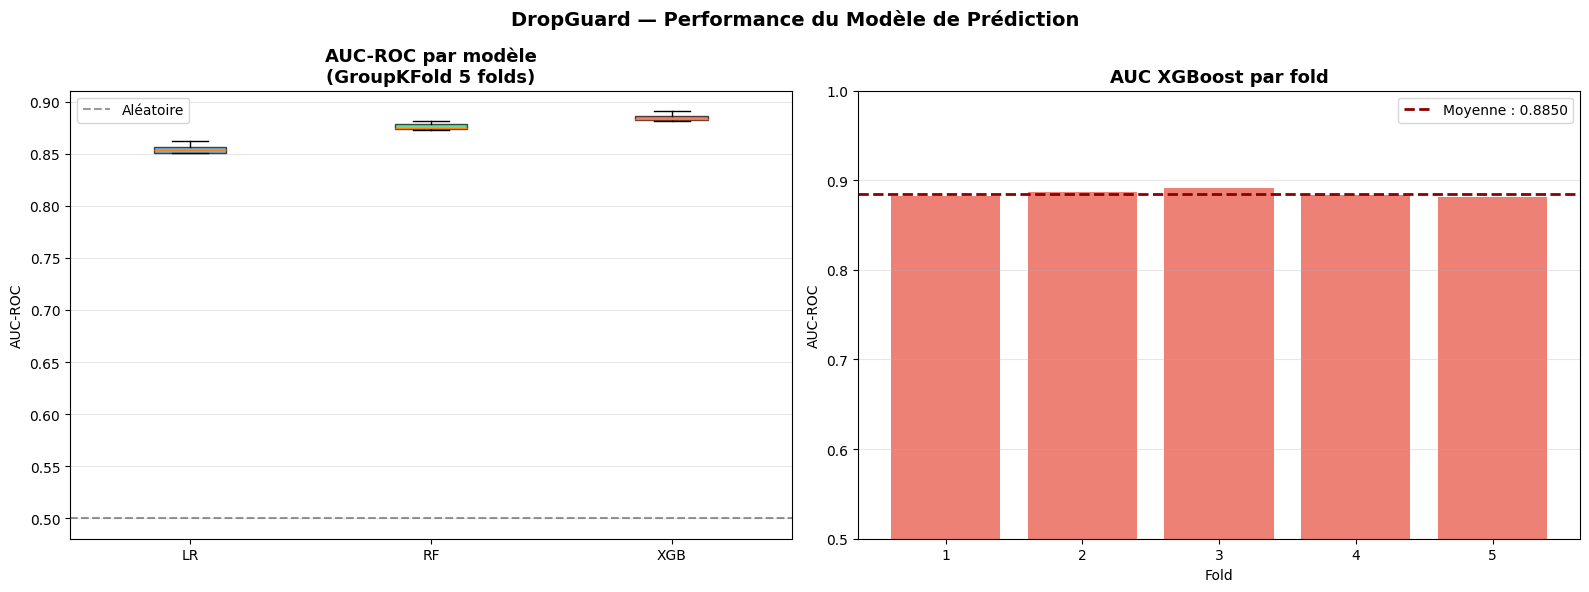

✅ Visualisation sauvegardée


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Graphe 1 — Boxplot AUC par modèle
model_order = ['Logistic Regression','Random Forest','XGBoost']
colors = ['#3498DB','#2ECC71','#E74C3C']

data_plot = [
    df_results[df_results['model']==m]['auc'].values
    for m in model_order
]

bp = axes[0].boxplot(data_plot, patch_artist=True,
                      labels=['LR','RF','XGB'])
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

axes[0].set_title('AUC-ROC par modèle\n(GroupKFold 5 folds)',
                   fontsize=13, fontweight='bold')
axes[0].set_ylabel('AUC-ROC')
axes[0].axhline(0.5, color='black', linestyle='--',
                alpha=0.4, label='Aléatoire')
axes[0].grid(axis='y', alpha=0.3)
axes[0].legend()

# Graphe 2 — AUC XGBoost par fold
xgb_data = df_results[df_results['model']=='XGBoost']
axes[1].bar(xgb_data['fold'],
            xgb_data['auc'],
            color='#E74C3C', alpha=0.7)
axes[1].axhline(xgb_data['auc'].mean(),
                color='darkred', linestyle='--',
                linewidth=2,
                label=f"Moyenne : {xgb_data['auc'].mean():.4f}")
axes[1].set_title('AUC XGBoost par fold',
                   fontsize=13, fontweight='bold')
axes[1].set_xlabel('Fold')
axes[1].set_ylabel('AUC-ROC')
axes[1].set_ylim([0.5, 1.0])
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.suptitle('DropGuard — Performance du Modèle de Prédiction',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/model_comparison.png",
            dpi=300, bbox_inches='tight')
plt.show()
print("✅ Visualisation sauvegardée")

In [10]:
print("="*70)
print("  ENTRAÎNEMENT MODÈLE FINAL DROPGUARD")
print("="*70)

# Split train/test par étudiant (80/20)
unique_students = df['id_student'].unique()
np.random.seed(RANDOM_STATE)
np.random.shuffle(unique_students)

n_test         = int(0.2 * len(unique_students))
test_students  = set(unique_students[:n_test])
train_students = set(unique_students[n_test:])

train_mask = df['id_student'].isin(train_students)
test_mask  = df['id_student'].isin(test_students)

X_train = X[train_mask.values]
y_train = y[train_mask.values]
X_test  = X[test_mask.values]
y_test  = y[test_mask.values]

# Validation interne pour early stopping
val_size   = int(0.125 * len(train_students))
val_studs  = set(list(train_students)[:val_size])
tr_studs   = train_students - val_studs

tr_mask  = df['id_student'].isin(tr_studs) & train_mask
val_mask = df['id_student'].isin(val_studs) & train_mask

X_tr  = X[tr_mask.values]
y_tr  = y[tr_mask.values]
X_val = X[val_mask.values]
y_val = y[val_mask.values]

neg_f    = (y_tr == 0).sum()
pos_f    = (y_tr == 1).sum()

print(f"Train    : {len(X_tr):,} | Val : {len(X_val):,} | Test : {len(X_test):,}")
print(f"Overlap  : 0 étudiants ✅")

model_final = XGBClassifier(
    objective         = 'binary:logistic',
    eval_metric       = 'auc',
    scale_pos_weight  = neg_f / pos_f,
    eta               = 0.05,
    max_depth         = 6,
    subsample         = 0.8,
    colsample_bytree  = 0.8,
    n_estimators      = 1000,
    early_stopping_rounds = 50,
    random_state      = RANDOM_STATE,
    verbosity         = 0,
    n_jobs            = -1
)

model_final.fit(
    X_tr, y_tr,
    eval_set              = [(X_val, y_val)],
    verbose               = False
)

# Évaluation sur test
y_proba_test = model_final.predict_proba(X_test)[:, 1]
y_pred_test  = (y_proba_test >= 0.5).astype(int)
auc_test     = roc_auc_score(y_test, y_proba_test)

print(f"\n  AUC-ROC Test     : {auc_test:.4f}")
print(f"  Best iteration   : {model_final.best_iteration}")
print(f"\n{classification_report(y_test, y_pred_test, target_names=['Non-abandon','Abandon'])}")
print("✅ Modèle final entraîné")

  ENTRAÎNEMENT MODÈLE FINAL DROPGUARD
Train    : 114,385 | Val : 16,060 | Test : 32,520
Overlap  : 0 étudiants ✅

  AUC-ROC Test     : 0.8908
  Best iteration   : 175

              precision    recall  f1-score   support

 Non-abandon       0.89      0.86      0.87     22220
     Abandon       0.72      0.77      0.74     10300

    accuracy                           0.83     32520
   macro avg       0.80      0.82      0.81     32520
weighted avg       0.84      0.83      0.83     32520

✅ Modèle final entraîné


  ANALYSE SHAP — Explicabilité

Top 15 features SHAP :
                             feature  importance
                    jours_inactivite    0.746837
                   last_activity_day    0.387008
                           avg_score    0.262125
                     code_module_GGG    0.200998
                  days_active_recent    0.191674
                     code_module_CCC    0.148217
           num_submitted_assessments    0.116414
                                 CMA    0.100634
                     code_module_BBB    0.098768
                   tendance_activite    0.087907
                                 TMA    0.083906
                       clicks_recent    0.073234
                     total_span_days    0.065889
highest_education_Lower_Than_A_Level    0.057685
                            gender_M    0.052555


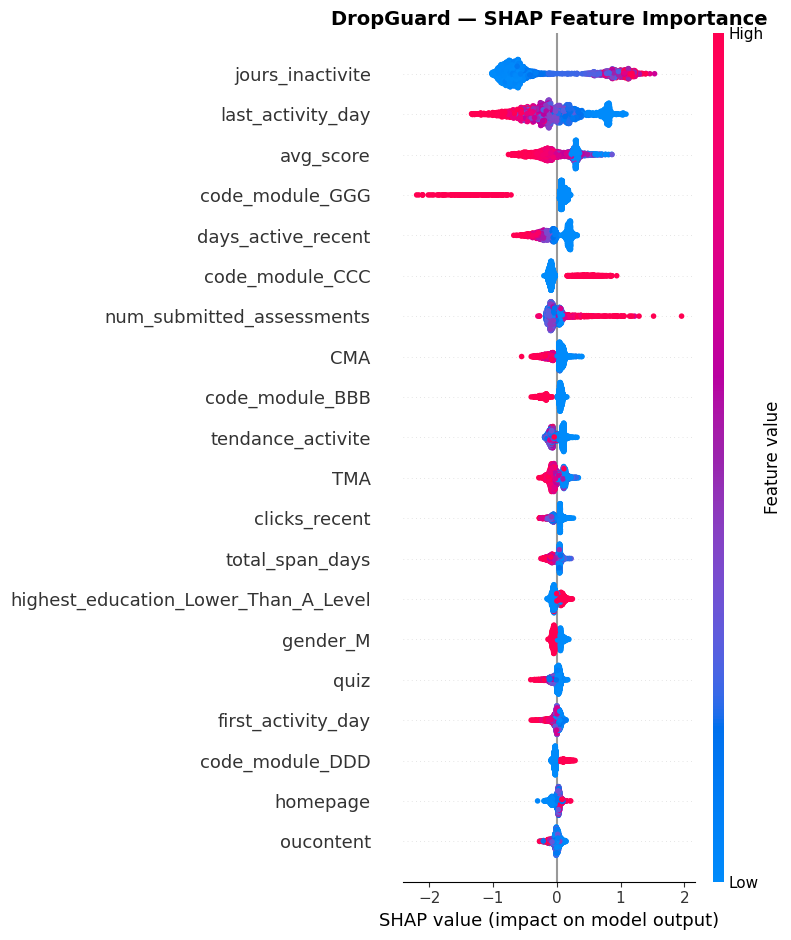

✅ SHAP terminé


In [11]:
print("="*70)
print("  ANALYSE SHAP — Explicabilité")
print("="*70)

explainer   = shap.TreeExplainer(model_final)
sample_idx  = np.random.choice(len(X_test),
                                min(2000, len(X_test)),
                                replace=False)
X_shap      = X_test.iloc[sample_idx]
shap_values = explainer.shap_values(X_shap)

# Importance globale
shap_importance = pd.DataFrame({
    'feature'   : X_shap.columns,
    'importance': np.abs(shap_values).mean(axis=0)
}).sort_values('importance', ascending=False)

print("\nTop 15 features SHAP :")
print(shap_importance.head(15).to_string(index=False))

# Summary plot
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_shap,
                  max_display=20, show=False)
plt.title('DropGuard — SHAP Feature Importance',
          fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/shap_summary.png",
            dpi=300, bbox_inches='tight')
plt.show()

shap_importance.to_csv(
    f"{METRICS_DIR}/shap_importance.csv", index=False
)
print("✅ SHAP terminé")

  TRAJECTOIRES DE RISQUE

  Total étudiants      : 32,593
  Critiques dès J28    : 6,790 (20.8%)
  Bascule à J56        : 421 (1.3%)
  Récupération J28→J84 : 338 (1.0%)


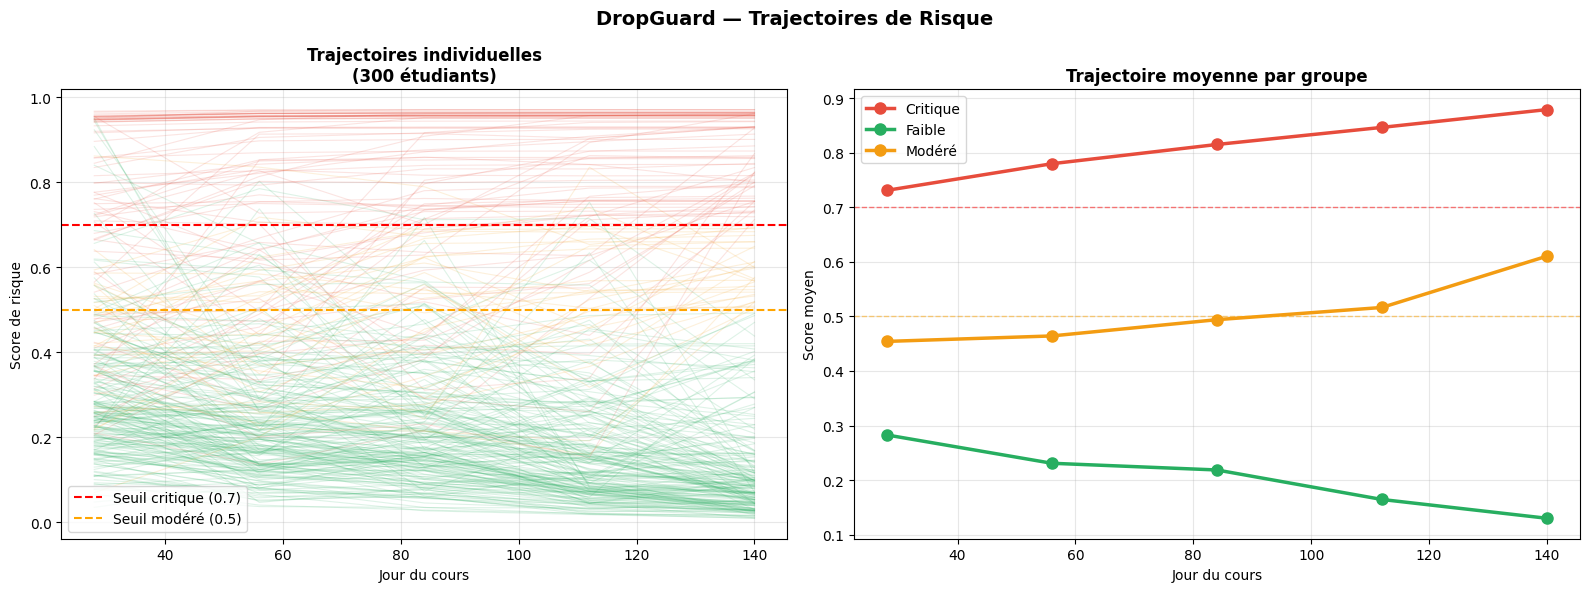

✅ Trajectoires terminées


In [12]:
print("="*70)
print("  TRAJECTOIRES DE RISQUE")
print("="*70)

# Calculer scores pour chaque cutoff
trajectory_records = []

for cutoff in [28, 56, 84, 112, 140]:
    df_c = pd.read_csv(
        f"{PROCESSED_PATH}/oulad_enriched_cutoff_{cutoff}.csv"
    )
    X_c, y_c = prepare_features(df_c, FEATURE_COLS)

    # Aligner colonnes avec modèle final
    for col in X.columns:
        if col not in X_c.columns:
            X_c[col] = 0
    X_c = X_c[X.columns].fillna(0)

    scores = model_final.predict_proba(X_c)[:, 1]

    for i, (idx, row) in enumerate(df_c.iterrows()):
        trajectory_records.append({
            'id_student'       : row['id_student'],
            'code_module'      : row['code_module'],
            'code_presentation': row['code_presentation'],
            'is_withdrawn'     : row['is_withdrawn'],
            'cutoff_day'       : cutoff,
            'dropout_score'    : scores[i]
        })

df_traj = pd.DataFrame(trajectory_records)

# Pivot par cutoff
df_pivot = df_traj.pivot_table(
    index=['id_student','code_module',
           'code_presentation','is_withdrawn'],
    columns='cutoff_day',
    values='dropout_score'
).reset_index()

df_pivot.columns = [
    'id_student','code_module','code_presentation',
    'is_withdrawn','score_j28','score_j56',
    'score_j84','score_j112','score_j140'
]

# Statistiques trajectoires
alerte_j56 = (
    (df_pivot['score_j28'] < 0.5) &
    (df_pivot['score_j56'] >= 0.7)
).sum()

critique_precoce = (df_pivot['score_j28'] >= 0.7).sum()
recuperation = (
    (df_pivot['score_j28'] >= 0.7) &
    (df_pivot['score_j84'] < 0.5)
).sum()

total = len(df_pivot)
print(f"\n  Total étudiants      : {total:,}")
print(f"  Critiques dès J28    : {critique_precoce:,} ({100*critique_precoce/total:.1f}%)")
print(f"  Bascule à J56        : {alerte_j56:,} ({100*alerte_j56/total:.1f}%)")
print(f"  Récupération J28→J84 : {recuperation:,} ({100*recuperation/total:.1f}%)")

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Trajectoires individuelles (sample 300)
sample = df_pivot.sample(300, random_state=42)
cutoff_cols = ['score_j28','score_j56','score_j84',
               'score_j112','score_j140']
cutoff_days = [28, 56, 84, 112, 140]

for _, row in sample.iterrows():
    scores_row = [row[c] for c in cutoff_cols]
    final_score = row['score_j140']
    color = ('#E74C3C' if final_score >= 0.7
             else '#F39C12' if final_score >= 0.5
             else '#27AE60')
    axes[0].plot(cutoff_days, scores_row,
                 color=color, alpha=0.15, linewidth=0.8)

axes[0].axhline(0.7, color='red', linestyle='--',
                linewidth=1.5, label='Seuil critique (0.7)')
axes[0].axhline(0.5, color='orange', linestyle='--',
                linewidth=1.5, label='Seuil modéré (0.5)')
axes[0].set_xlabel('Jour du cours')
axes[0].set_ylabel('Score de risque')
axes[0].set_title('Trajectoires individuelles\n(300 étudiants)',
                   fontsize=12, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Trajectoires moyennes par groupe
def groupe(row):
    if row['score_j140'] >= 0.7: return 'Critique'
    elif row['score_j140'] >= 0.5: return 'Modéré'
    else: return 'Faible'

df_pivot['groupe'] = df_pivot.apply(groupe, axis=1)
grouped = df_pivot.groupby('groupe')[cutoff_cols].mean()

colors_g = {'Critique':'#E74C3C',
            'Modéré':'#F39C12',
            'Faible':'#27AE60'}

for grp, row in grouped.iterrows():
    axes[1].plot(cutoff_days,
                 [row[c] for c in cutoff_cols],
                 marker='o', linewidth=2.5,
                 markersize=8,
                 color=colors_g.get(grp,'#3498DB'),
                 label=grp)

axes[1].axhline(0.7, color='red', linestyle='--',
                linewidth=1, alpha=0.5)
axes[1].axhline(0.5, color='orange', linestyle='--',
                linewidth=1, alpha=0.5)
axes[1].set_xlabel('Jour du cours')
axes[1].set_ylabel('Score moyen')
axes[1].set_title('Trajectoire moyenne par groupe',
                   fontsize=12, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('DropGuard — Trajectoires de Risque',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/trajectoires_risque.png",
            dpi=300, bbox_inches='tight')
plt.show()

df_pivot.to_csv(f"{METRICS_DIR}/trajectoires_risque.csv",
                index=False)
print("✅ Trajectoires terminées")

In [13]:
print("="*70)
print("  SAUVEGARDE FINALE")
print("="*70)

# Modèle final
joblib.dump(model_final,
            f"{MODELS_DIR}/xgboost_dropguard_final.joblib")

# Features du modèle
feature_names = list(X.columns)
with open(f"{MODELS_DIR}/feature_names_final.json", 'w') as f:
    json.dump(feature_names, f, indent=2)

# Scores dropout sur dataset complet
scores_all = model_final.predict_proba(X)[:, 1]
df_scores  = df[['id_student','code_module',
                  'code_presentation','cutoff_day',
                  'is_withdrawn']].copy()
df_scores['dropout_score'] = scores_all
df_scores.to_csv(
    f"{PROCESSED_PATH}/dropout_scores_final.csv",
    index=False
)

print(f"\n  Fichiers sauvegardés :")
print(f"  ✅ xgboost_dropguard_final.joblib")
print(f"  ✅ feature_names_final.json")
print(f"  ✅ dropout_scores_final.csv")
print(f"\n{'='*70}")
print(f"  NB03 TERMINÉ — MODÈLE DROPGUARD FINAL")
print(f"{'='*70}")
print(f"  AUC-ROC Test     : {auc_test:.4f}")
print(f"  Features         : {len(feature_names)}")
print(f"  Cutoffs couverts : J28 → J140")
print(f"  Étudiants train  : {len(train_students):,}")
print(f"  Étudiants test   : {len(test_students):,}")
print(f"  Modèle prêt pour le plugin Moodle ✅")

  SAUVEGARDE FINALE

  Fichiers sauvegardés :
  ✅ xgboost_dropguard_final.joblib
  ✅ feature_names_final.json
  ✅ dropout_scores_final.csv

  NB03 TERMINÉ — MODÈLE DROPGUARD FINAL
  AUC-ROC Test     : 0.8908
  Features         : 85
  Cutoffs couverts : J28 → J140
  Étudiants train  : 23,028
  Étudiants test   : 5,757
  Modèle prêt pour le plugin Moodle ✅
